# Semana 6 Repositorios iteradores y rendimiento

Completar y comprobar los repositorios, consultas, recorridos y mediciones presentes en la carpeta de la semana 6, adaptándolos también al hotel.

Identificador S6-001. Completar ApellidoNombre antes de entregar. Solución elaborada con asistencia de IA. No equivale a una sustentación realizada.


## Preparar archivos

Las celdas writefile guardan las fuentes visibles en el entorno de Colab. Ejecutarlas en orden. Se requiere Python 3.12 o superior y g++ con C++17.


In [ ]:
from pathlib import Path
for carpeta in ["python", "cpp", "tests", ".build", "evidencias"]:
    Path(carpeta).mkdir(exist_ok=True)


### python\__init__.py

In [ ]:
%%writefile python/__init__.py


### python\benchmark.py

In [ ]:
%%writefile python/benchmark.py
"""Construcción y búsqueda medidas por separado; consultas iguales y reproducibles."""

import bisect
import csv
import statistics
import time
from pathlib import Path


def medir(funcion, repeticiones=3):
    muestras = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        valor = funcion()
        muestras.append((time.perf_counter() - inicio) * 1000)
    return statistics.median(muestras), valor


def benchmark():
    filas = []
    for n in [1000, 10000, 100000, 1000000]:
        consultas = [(i * 7919 + 206) % (2 * n) for i in range(200)]
        for nombre, crear in [
            ("list", lambda: list(range(n))),
            ("dict", lambda: dict.fromkeys(range(n))),
            ("set", lambda: set(range(n))),
            ("bisect", lambda: list(range(n))),
        ]:
            construccion, contenedor = medir(crear)
            if nombre == "bisect":

                def buscar():
                    total = 0
                    for q in consultas:
                        posicion = bisect.bisect_left(contenedor, q)
                        total += posicion < len(contenedor) and contenedor[posicion] == q
                    return total

            else:

                def buscar():
                    return sum(q in contenedor for q in consultas)

            busqueda, aciertos = medir(buscar)
            filas.append(
                {
                    "lenguaje": "Python",
                    "n": n,
                    "estructura": nombre,
                    "consultas": 200,
                    "repeticiones": 3,
                    "construccion_ms": construccion,
                    "busqueda_lote_ms": busqueda,
                    "aciertos": aciertos,
                }
            )
    salida = Path(__file__).resolve().parents[1] / "evidencias/benchmark_python.csv"
    salida.parent.mkdir(parents=True, exist_ok=True)
    with salida.open("w", newline="", encoding="utf-8") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=filas[0].keys())
        escritor.writeheader()
        escritor.writerows(filas)
    print("Benchmark Python guardado con tiempos medidos y construccion separada.")


if __name__ == "__main__":
    benchmark()


### python\errores_hotel.py

In [ ]:
%%writefile python/errores_hotel.py
"""Errores del dominio hotelero y verificadores de contratos."""

from .hotel_base import Habitacion, Reserva
from .result import Result


class ErrorHotel(Exception):
    pass


class ErrorDatosHotel(ErrorHotel):
    pass


class ErrorEstadoReserva(ErrorHotel):
    pass


class ErrorDisponibilidad(ErrorHotel):
    pass


class HabitacionRobusta(Habitacion):
    def __init__(self, *args):
        try:
            super().__init__(*args)
        except (ValueError, RuntimeError) as causa:
            raise ErrorDatosHotel(str(causa)) from causa
        self._verificar_invariante()

    def _verificar_invariante(self):
        assert self.numero > 0 and self.tarifa > 0
        assert 0 <= self.plazas_libres <= self.capacidad

    def alojar(self, cantidad):
        try:
            super().alojar(cantidad)
        except (ValueError, RuntimeError) as causa:
            raise ErrorDisponibilidad(str(causa)) from causa
        self._verificar_invariante()


class ReservaRobusta(Reserva):
    def __init__(self, *args):
        try:
            super().__init__(*args)
        except (ValueError, RuntimeError) as causa:
            raise ErrorDatosHotel(str(causa)) from causa
        self._verificar_invariante()

    def _verificar_invariante(self):
        assert self.codigo.strip() and self.noches > 0
        assert self.estado in {"REGISTRADA", "CONFIRMADA", "ANULADA"}

    def confirmar(self):
        try:
            super().confirmar()
        except RuntimeError as causa:
            raise ErrorEstadoReserva(str(causa)) from causa
        self._verificar_invariante()

    def anular(self):
        try:
            super().anular()
        except RuntimeError as causa:
            raise ErrorEstadoReserva(str(causa)) from causa
        self._verificar_invariante()


def buscar_habitacion(habitaciones, numero):
    return next(
        (Result.ok(h) for h in habitaciones if h.numero == numero),
        Result.fallo("Habitacion no encontrada"),
    )


### python\hotel_base.py

In [ ]:
%%writefile python/hotel_base.py
"""Modelo inicial del proyecto hotelero correspondiente a la semana 2."""

from datetime import date
from math import isfinite


def texto(valor):
    if not isinstance(valor, str) or not valor.strip():
        raise ValueError("Texto no vacio requerido")
    return valor


def entero(valor, minimo, maximo):
    if type(valor) is not int or not minimo <= valor <= maximo:
        raise ValueError("Entero fuera de rango")
    return valor


class Huesped:
    def __init__(self, identificador, nombre, documento):
        self.__id = texto(identificador)
        self.nombre = nombre
        self.documento = documento

    @property
    def id(self):
        return self.__id

    @property
    def nombre(self):
        return self.__nombre

    @nombre.setter
    def nombre(self, valor):
        self.__nombre = texto(valor)

    @property
    def documento(self):
        return self.__documento

    @documento.setter
    def documento(self, valor):
        if (
            not isinstance(valor, str)
            or len(valor) != 8
            or not valor.isascii()
            or not valor.isdigit()
        ):
            raise ValueError("DNI debe tener ocho digitos ASCII")
        self.__documento = valor

    @property
    def etiqueta(self):
        return f"{self.id} {self.nombre}"

    def actualizar_documento(self, documento):
        self.documento = documento


class Habitacion:
    def __init__(self, numero, tipo, capacidad, tarifa):
        self.__numero = entero(numero, 1, 9999)
        self.__ocupantes = 0
        self.tipo = tipo
        self.capacidad = capacidad
        self.tarifa = tarifa

    @property
    def numero(self):
        return self.__numero

    @property
    def tipo(self):
        return self.__tipo

    @tipo.setter
    def tipo(self, valor):
        self.__tipo = texto(valor)

    @property
    def capacidad(self):
        return self.__capacidad

    @capacidad.setter
    def capacidad(self, valor):
        entero(valor, 1, 10)
        if valor < self.__ocupantes:
            raise ValueError("Capacidad menor que ocupantes")
        self.__capacidad = valor

    @property
    def tarifa(self):
        return self.__tarifa

    @tarifa.setter
    def tarifa(self, valor):
        if (
            isinstance(valor, bool)
            or not isinstance(valor, (float, int))
            or not isfinite(valor)
            or valor <= 0
        ):
            raise ValueError("Tarifa positiva finita requerida")
        self.__tarifa = float(valor)

    @property
    def plazas_libres(self):
        return self.capacidad - self.__ocupantes

    def alojar(self, cantidad):
        entero(cantidad, 1, 10)
        if cantidad > self.plazas_libres:
            raise RuntimeError("Sin plazas")
        self.__ocupantes += cantidad

    def liberar(self):
        self.__ocupantes = 0

    def precio_noche(self):
        return self.tarifa


class Reserva:
    def __init__(self, codigo, entrada, salida):
        self.__codigo = texto(codigo)
        self.__entrada = date.fromisoformat(entrada)
        self.__salida = date.fromisoformat(salida)
        if self.__salida <= self.__entrada:
            raise ValueError("Salida debe ser posterior")
        self.__estado = "REGISTRADA"

    @property
    def codigo(self):
        return self.__codigo

    @property
    def entrada(self):
        return self.__entrada.isoformat()

    @property
    def salida(self):
        return self.__salida.isoformat()

    @property
    def noches(self):
        return (self.__salida - self.__entrada).days

    @property
    def estado(self):
        return self.__estado

    def confirmar(self):
        if self.estado != "REGISTRADA":
            raise RuntimeError("Confirmacion no permitida")
        self.__estado = "CONFIRMADA"

    def anular(self):
        if self.estado == "ANULADA":
            raise RuntimeError("Reserva ya anulada")
        self.__estado = "ANULADA"


### python\hotel_herencia.py

In [ ]:
%%writefile python/hotel_herencia.py
"""Semana 3: las categorías son habitaciones y conservan el contrato de precio."""

from .hotel_base import Habitacion


class HabitacionSimple(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Simple", 1, tarifa)

    def precio_noche(self):
        return self.tarifa


class HabitacionDoble(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Doble", 2, tarifa)

    def precio_noche(self):
        return self.tarifa * 1.5


class Suite(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Suite", 4, tarifa)

    def precio_noche(self):
        return self.tarifa * 2


def cotizar_habitaciones(habitaciones):
    return [h.precio_noche() for h in habitaciones]


### python\main.py

In [ ]:
%%writefile python/main.py
from .solucion import demo

if __name__ == "__main__":
    print("\n".join(demo()))


### python\repositorio.py

In [ ]:
%%writefile python/repositorio.py
"""Repositorio genérico: guardar actualiza; insertar rechaza un ID repetido."""

from collections import deque
from functools import reduce
from typing import Generic, TypeVar, Callable, Iterator
from .result import Result

T = TypeVar("T")
ID = TypeVar("ID")


class Repositorio(Generic[T, ID]):
    def __init__(self, fn_id: Callable[[T], ID]):
        if not callable(fn_id):
            raise ValueError("Extractor de ID requerido")
        self._fn_id, self._datos = fn_id, {}

    def guardar(self, entidad: T):
        self._datos[self._fn_id(entidad)] = entidad

    def insertar(self, entidad: T):
        if self.existe(self._fn_id(entidad)):
            raise ValueError("ID duplicado")
        self.guardar(entidad)

    def buscar(self, identificador: ID):
        return self._datos.get(identificador)

    def buscar_resultado(self, identificador: ID):
        if identificador in self._datos:
            return Result.ok(self._datos[identificador])
        return Result.fallo("Recurso no encontrado")

    def eliminar(self, identificador: ID):
        if identificador not in self._datos:
            return False
        del self._datos[identificador]
        return True

    def todos(self):
        return list(self._datos.values())

    def filtrar(self, predicado):
        return [e for e in self if predicado(e)]

    def ordenar(self, key, reverse=False):
        return sorted(self, key=key, reverse=reverse)

    def acumular(self, inicial, funcion):
        return reduce(funcion, self, inicial)

    def contar(self, predicado):
        return sum(1 for e in self if predicado(e))

    def existe(self, identificador):
        return identificador in self._datos

    def primero(self, predicado):
        return next((e for e in self if predicado(e)), None)

    def estadisticas(self, atributo):
        valores = [getattr(e, atributo) for e in self]
        return (
            {
                "min": min(valores),
                "max": max(valores),
                "promedio": sum(valores) / len(valores),
                "n": len(valores),
            }
            if valores
            else {"min": None, "max": None, "promedio": None, "n": 0}
        )

    def __len__(self):
        return len(self._datos)

    def __contains__(self, identificador):
        return self.existe(identificador)

    def __iter__(self) -> Iterator[T]:
        return iter(self._datos.values())


class ColaAtencion(Generic[T]):
    def __init__(self):
        self._cola = deque()

    def encolar(self, elemento: T):
        self._cola.append(elemento)

    def atender(self):
        return self._cola.popleft() if self._cola else None

    def __len__(self):
        return len(self._cola)

    def __iter__(self):
        return iter(self._cola)


class PlanillaIterador(Generic[T]):
    def __init__(self, personal, key=lambda p: p.calcular_remuneracion()):
        self._ordenados = sorted(personal, key=key, reverse=True)

    def __iter__(self):
        return iter(self._ordenados)


def ventana_deslizante(datos, k):
    if type(k) is not int or not 1 <= k <= len(datos):
        raise ValueError("Ventana fuera de 1 a longitud")
    for i in range(len(datos) - k + 1):
        yield datos[i : i + k]


### python\result.py

In [ ]:
%%writefile python/result.py
"""Result inmutable y discriminado; map encadena funciones que retornan Result."""

from dataclasses import dataclass
from typing import Generic, TypeVar, Callable

T = TypeVar("T")
U = TypeVar("U")


@dataclass(frozen=True)
class Result(Generic[T]):
    _exito: bool
    _dato: object

    def __post_init__(self):
        if type(self._exito) is not bool:
            raise TypeError("Discriminante booleano requerido")
        if not self._exito and (not isinstance(self._dato, str) or not self._dato):
            raise ValueError("Mensaje de error requerido")

    @staticmethod
    def ok(valor: T) -> "Result[T]":
        return Result(True, valor)

    @staticmethod
    def fallo(error: str) -> "Result[T]":
        return Result(False, error)

    @property
    def es_exito(self):
        return self._exito

    @property
    def valor(self) -> T:
        if not self.es_exito:
            raise RuntimeError("Result fallido: " + str(self._dato))
        return self._dato

    @property
    def error(self):
        if self.es_exito:
            raise RuntimeError("Un exito no tiene error")
        return self._dato

    def map(self, f: Callable[[T], "Result[U]"]) -> "Result[U]":
        if not self.es_exito:
            return Result.fallo(self.error)
        resultado = f(self.valor)
        if not isinstance(resultado, Result):
            raise TypeError("map espera una funcion que retorne Result")
        return resultado


### python\solucion.py

In [ ]:
%%writefile python/solucion.py
"""Consultas académicas y adaptación hotelera a partir del código disponible."""

from dataclasses import dataclass
from .repositorio import Repositorio, ColaAtencion, PlanillaIterador, ventana_deslizante
from .hotel_herencia import HabitacionSimple, HabitacionDoble, Suite


@dataclass(frozen=True)
class Estudiante:
    codigo: int
    nombre: str
    ppa: float
    escuela: str


def crear_repositorio():
    r = Repositorio(lambda e: e.codigo)
    for e in [
        Estudiante(1001, "Juan", 15.2, "Ing. Sistemas"),
        Estudiante(1002, "Maria", 18.5, "Ing. Sistemas"),
        Estudiante(1003, "Pedro", 9.8, "Ciencias Comp."),
        Estudiante(1004, "Ana", 13, "Ing. Sistemas"),
    ]:
        r.guardar(e)
    return r


def crear_hotel():
    r = Repositorio(lambda h: h.numero)
    for h in [HabitacionSimple(101), HabitacionDoble(102), Suite(103), HabitacionSimple(104, 120)]:
        r.guardar(h)
    return r


def demo():
    r = crear_repositorio()
    hotel = crear_hotel()
    c = ColaAtencion()
    c.encolar("Ana")
    c.encolar("Juan")
    ranking = r.ordenar(lambda e: e.ppa, reverse=True)
    return [
        f"DESTACADOS={r.contar(lambda e:e.ppa>=14 and e.escuela=='Ing. Sistemas')}",
        "RANKING=" + ",".join(str(e.codigo) for e in ranking),
        f"PROMEDIO={r.estadisticas('ppa')['promedio']:.3f}",
        f"HABITACIONES_DOS_PLAZAS={hotel.contar(lambda h:h.plazas_libres>=2)}",
        "RANKING_HOTEL="
        + ",".join(str(h.numero) for h in hotel.ordenar(lambda h: h.precio_noche(), reverse=True)),
        f"PROMEDIO_HOTEL={hotel.acumular(0,lambda s,h:s+h.precio_noche())/len(hotel):.2f}",
        f"FIFO={c.atender()}",
        f"VENTANAS={len(list(ventana_deslizante([12,15,18,14,16],3)))}",
    ]


### cpp\benchmark.cpp

In [ ]:
%%writefile cpp/benchmark.cpp
#include "comun.hpp"
#include <chrono>
#include <fstream>
#include <filesystem>
#include <numeric>
#include <unordered_map>
#include <unordered_set>
using Reloj = std::chrono::steady_clock;
inline double ms(Reloj::time_point inicio) {
    return std::chrono::duration<double, std::milli>(Reloj::now() - inicio).count();
}
template <class Crear, class Buscar>
void medir(std::ofstream &salida, int n, const std::string &nombre, Crear crear, Buscar buscar) {
    std::vector<double> construcciones, busquedas;
    int aciertos = 0;
    for (int repeticion = 0; repeticion < 3; ++repeticion) {
        auto inicio = Reloj::now();
        auto contenedor = crear();
        construcciones.push_back(ms(inicio));
        inicio = Reloj::now();
        int total = 0;
        for (int i = 0; i < 200; ++i) {
            int q = (i * 7919 + 206) % (2 * n);
            if (buscar(contenedor, q)) {
                ++total;
            }
        }
        busquedas.push_back(ms(inicio));
        aciertos = total;
    }
    std::sort(construcciones.begin(), construcciones.end());
    std::sort(busquedas.begin(), busquedas.end());
    salida << "Cpp," << n << ',' << nombre << ",200,3," << construcciones[1] << ',' << busquedas[1]
           << ',' << aciertos << '\n';
}
int main() {
    std::filesystem::create_directories("evidencias");
    std::ofstream salida("evidencias/benchmark_cpp.csv");
    if (!salida) {
        return 1;
    }
    salida << "lenguaje,n,estructura,consultas,repeticiones,construccion_ms,busqueda_lote_ms,"
              "aciertos\n";
    for (int n : {1000, 10000, 100000, 1000000}) {
        auto vector = [n] {
            std::vector<int> v(static_cast<std::size_t>(n));
            std::iota(v.begin(), v.end(), 0);
            return v;
        };
        medir(salida, n, "vector", vector,
              [](const auto &c, int q) { return std::find(c.begin(), c.end(), q) != c.end(); });
        medir(
            salida, n, "unordered_map",
            [n] {
                std::unordered_map<int, int> c;
                for (int i = 0; i < n; ++i) {
                    c.emplace(i, i);
                }
                return c;
            },
            [](const auto &c, int q) { return c.find(q) != c.end(); });
        medir(
            salida, n, "unordered_set",
            [n] {
                std::unordered_set<int> c;
                for (int i = 0; i < n; ++i) {
                    c.emplace(i);
                }
                return c;
            },
            [](const auto &c, int q) { return c.find(q) != c.end(); });
        medir(salida, n, "binary_search", vector,
              [](const auto &c, int q) { return std::binary_search(c.begin(), c.end(), q); });
    }
    std::cout << "Benchmark C++ guardado con tiempos medidos y construccion separada.\n";
}


### cpp\comun.hpp

In [ ]:
%%writefile cpp/comun.hpp
#pragma once
#include <algorithm>
#include <cassert>
#include <cmath>
#include <ctime>
#include <functional>
#include <iomanip>
#include <iostream>
#include <memory>
#include <regex>
#include <sstream>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

inline void exigir(bool condicion) {
    if (!condicion) {
        throw std::runtime_error("No coincide con el contrato esperado");
    }
}
template <class Error = std::exception, class F> void debeFallar(F accion) {
    bool fallo = false;
    try {
        accion();
    } catch (const Error &) {
        fallo = true;
    }
    exigir(fallo);
}
struct Pruebas {
    int total = 0, correctas = 0;
    template <class F> void caso(const std::string &nombre, F accion) {
        ++total;
        try {
            accion();
            ++correctas;
            std::cout << "OK " << nombre << '\n';
        } catch (const std::exception &e) {
            std::cerr << "FALLO " << nombre << ": " << e.what() << '\n';
        }
    }
    int terminar() const {
        std::cout << correctas << '/' << total << " pruebas aprobadas\n";
        return total == correctas ? 0 : 1;
    }
};
inline void textoValido(const std::string &v) {
    if (v.find_first_not_of(" \t\r\n") == std::string::npos) {
        throw std::invalid_argument("Texto vacio");
    }
}
inline void positivo(double v) {
    if (!std::isfinite(v) || v <= 0) {
        throw std::invalid_argument("Valor positivo requerido");
    }
}
inline bool bisiesto(int y) {
    return y % 4 == 0 && (y % 100 != 0 || y % 400 == 0);
}
inline int ordinal(const std::string &fecha) {
    if (!std::regex_match(fecha, std::regex("[0-9]{4}-[0-9]{2}-[0-9]{2}"))) {
        throw std::invalid_argument("Fecha ISO requerida");
    }
    int y = std::stoi(fecha.substr(0, 4)), m = std::stoi(fecha.substr(5, 2)),
        d = std::stoi(fecha.substr(8, 2));
    const int dias[] = {31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31};
    if (y < 1 || m < 1 || m > 12 || d < 1 || d > dias[m - 1] + (m == 2 && bisiesto(y))) {
        throw std::invalid_argument("Fecha inexistente");
    }
    int n = 365 * (y - 1) + (y - 1) / 4 - (y - 1) / 100 + (y - 1) / 400 + d;
    for (int i = 1; i < m; ++i) {
        n += dias[i - 1] + (i == 2 && bisiesto(y));
    }
    return n;
}
inline std::string hoyISO() {
    auto ahora = std::time(nullptr);
    auto *fecha = std::localtime(&ahora);
    if (!fecha) {
        throw std::runtime_error("Reloj no disponible");
    }
    std::ostringstream out;
    out << std::put_time(fecha, "%Y-%m-%d");
    return out.str();
}


### cpp\errores_hotel.hpp

In [ ]:
%%writefile cpp/errores_hotel.hpp
#pragma once
#include "hotel_base.hpp"
#include "result.hpp"
class ErrorHotel : public std::runtime_error {
  public:
    using std::runtime_error::runtime_error;
    virtual ~ErrorHotel() = default;
};
class ErrorDatosHotel : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};
class ErrorEstadoReserva : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};
class ErrorDisponibilidad : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};
class HabitacionRobusta : public Habitacion {
  public:
    HabitacionRobusta(int numero, const std::string &tipo, int capacidad, double tarifa) try
        : Habitacion(numero, tipo, capacidad, tarifa) {
        verificarInvariante();
    } catch (const std::invalid_argument &e) {
        throw ErrorDatosHotel(e.what());
    }
    void verificarInvariante() const {
        assert(numero() > 0 && tarifa() > 0);
        assert(plazasLibres() >= 0 && plazasLibres() <= capacidad());
    }
    void alojar(int n) {
        try {
            Habitacion::alojar(n);
        } catch (const std::runtime_error &e) {
            throw ErrorDisponibilidad(e.what());
        }
        verificarInvariante();
    }
};
class ReservaRobusta : public Reserva {
  public:
    ReservaRobusta(const std::string &codigo, const std::string &entrada,
                   const std::string &salida) try
        : Reserva(codigo, entrada, salida) {
        verificarInvariante();
    } catch (const std::invalid_argument &e) {
        throw ErrorDatosHotel(e.what());
    }
    void verificarInvariante() const {
        assert(!codigo().empty() && noches() > 0);
    }
    void confirmar() {
        try {
            Reserva::confirmar();
        } catch (const std::runtime_error &e) {
            throw ErrorEstadoReserva(e.what());
        }
        verificarInvariante();
    }
    void anular() {
        try {
            Reserva::anular();
        } catch (const std::runtime_error &e) {
            throw ErrorEstadoReserva(e.what());
        }
        verificarInvariante();
    }
};
inline Result<std::shared_ptr<Habitacion>>
buscarHabitacion(const std::vector<std::shared_ptr<Habitacion>> &hs, int numero) {
    for (const auto &h : hs) {
        if (h && h->numero() == numero) {
            return Result<std::shared_ptr<Habitacion>>::ok(h);
        }
    }
    return Result<std::shared_ptr<Habitacion>>::fallo("Habitacion no encontrada");
}


### cpp\hotel_base.hpp

In [ ]:
%%writefile cpp/hotel_base.hpp
#pragma once
#include "comun.hpp"

class Huesped {
    std::string id_, nombre_, documento_;

  public:
    Huesped(std::string id, std::string nombre, std::string documento) : id_(std::move(id)) {
        textoValido(id_);
        setNombre(nombre);
        setDocumento(documento);
    }
    const std::string &id() const noexcept {
        return id_;
    }
    const std::string &nombre() const noexcept {
        return nombre_;
    }
    const std::string &documento() const noexcept {
        return documento_;
    }
    void setNombre(const std::string &v) {
        textoValido(v);
        nombre_ = v;
    }
    void setDocumento(const std::string &v) {
        if (!std::regex_match(v, std::regex("[0-9]{8}"))) {
            throw std::invalid_argument("DNI invalido");
        }
        documento_ = v;
    }
    std::string etiqueta() const {
        return id_ + " " + nombre_;
    }
    void actualizarDocumento(const std::string &v) {
        setDocumento(v);
    }
};

class Habitacion {
    int numero_, capacidad_ = 1, ocupantes_ = 0;
    std::string tipo_;
    double tarifa_ = 1;

  public:
    Habitacion(int numero, const std::string &tipo, int capacidad, double tarifa)
        : numero_(numero) {
        if (numero < 1 || numero > 9999) {
            throw std::invalid_argument("Numero invalido");
        }
        setTipo(tipo);
        setCapacidad(capacidad);
        setTarifa(tarifa);
    }
    virtual ~Habitacion() = default;
    int numero() const noexcept {
        return numero_;
    }
    int capacidad() const noexcept {
        return capacidad_;
    }
    const std::string &tipo() const noexcept {
        return tipo_;
    }
    double tarifa() const noexcept {
        return tarifa_;
    }
    void setTipo(const std::string &v) {
        textoValido(v);
        tipo_ = v;
    }
    void setCapacidad(int v) {
        if (v < 1 || v > 10 || v < ocupantes_) {
            throw std::invalid_argument("Capacidad invalida");
        }
        capacidad_ = v;
    }
    void setTarifa(double v) {
        positivo(v);
        tarifa_ = v;
    }
    int plazasLibres() const noexcept {
        return capacidad_ - ocupantes_;
    }
    void alojar(int cantidad) {
        if (cantidad <= 0 || cantidad > plazasLibres()) {
            throw std::runtime_error("Sin plazas");
        }
        ocupantes_ += cantidad;
    }
    void liberar() noexcept {
        ocupantes_ = 0;
    }
    virtual double precioNoche() const {
        return tarifa_;
    }
};

class Reserva {
    std::string codigo_, entrada_, salida_, estado_ = "REGISTRADA";

  public:
    Reserva(std::string codigo, std::string entrada, std::string salida)
        : codigo_(std::move(codigo)), entrada_(std::move(entrada)), salida_(std::move(salida)) {
        textoValido(codigo_);
        if (ordinal(salida_) <= ordinal(entrada_)) {
            throw std::invalid_argument("Salida debe ser posterior");
        }
    }
    const std::string &codigo() const noexcept {
        return codigo_;
    }
    const std::string &entrada() const noexcept {
        return entrada_;
    }
    const std::string &salida() const noexcept {
        return salida_;
    }
    const std::string &estado() const noexcept {
        return estado_;
    }
    int noches() const {
        return ordinal(salida_) - ordinal(entrada_);
    }
    void confirmar() {
        if (estado_ != "REGISTRADA") {
            throw std::runtime_error("Confirmacion no permitida");
        }
        estado_ = "CONFIRMADA";
    }
    void anular() {
        if (estado_ == "ANULADA") {
            throw std::runtime_error("Reserva ya anulada");
        }
        estado_ = "ANULADA";
    }
};


### cpp\hotel_herencia.hpp

In [ ]:
%%writefile cpp/hotel_herencia.hpp
#pragma once
#include "hotel_base.hpp"
class HabitacionSimple : public Habitacion {
  public:
    explicit HabitacionSimple(int numero, double tarifa = 100)
        : Habitacion(numero, "Simple", 1, tarifa) {}
    double precioNoche() const override {
        return tarifa();
    }
};
class HabitacionDoble : public Habitacion {
  public:
    explicit HabitacionDoble(int numero, double tarifa = 100)
        : Habitacion(numero, "Doble", 2, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 1.5;
    }
};
class Suite : public Habitacion {
  public:
    explicit Suite(int numero, double tarifa = 100) : Habitacion(numero, "Suite", 4, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 2;
    }
};


### cpp\main.cpp

In [ ]:
%%writefile cpp/main.cpp
#include "solucion.hpp"
int main() {
    demo();
}


### cpp\pruebas.cpp

In [ ]:
%%writefile cpp/pruebas.cpp
#include "solucion.hpp"
int main() {
    Pruebas t;
    t.caso("guardar buscar", [] {
        auto r = crearRepositorio();
        exigir(r.buscar(1001)->nombre == "Juan");
    });
    t.caso("guardar actualiza", [] {
        auto r = crearRepositorio();
        r.guardar({1001, "Otro", 16, "Sistemas"});
        exigir(r.tamano() == 4 && r.buscar(1001)->nombre == "Otro");
    });
    t.caso("insertar duplicado", [] {
        auto r = crearRepositorio();
        debeFallar([&] { r.insertar({1001, "Otro", 16, "Sistemas"}); });
    });
    t.caso("eliminar cero", [] {
        Repositorio<int, int> r([](int n) { return n; });
        r.guardar(0);
        exigir(r.eliminar(0) && !r.eliminar(0));
    });
    t.caso("busqueda ausente", [] { exigir(!crearRepositorio().buscarResultado(9999).esExito()); });
    t.caso("filtrar contar", [] {
        auto r = crearRepositorio();
        exigir(r.contar(
                   [](const auto &e) { return e.ppa >= 14 && e.escuela == "Ing. Sistemas"; }) == 2);
    });
    t.caso("ordenar", [] {
        auto v =
            crearRepositorio().ordenar([](const auto &a, const auto &b) { return a.ppa > b.ppa; });
        exigir(v[0].codigo == 1002 && v[3].codigo == 1003);
    });
    t.caso("acumular", [] {
        auto r = crearRepositorio();
        exigir(std::abs(r.acumular(0.0, [](double a, const auto &e) { return a + e.ppa; }) /
                            r.tamano() -
                        14.125) < 0.0001);
    });
    t.caso("lista copia", [] {
        auto r = crearRepositorio();
        auto v = r.todos();
        v.clear();
        exigir(r.tamano() == 4);
    });
    t.caso("cola fifo", [] {
        ColaAtencion<int> c;
        c.encolar(0);
        c.encolar(1);
        exigir(*c.atender() == 0 && *c.atender() == 1 && !c.atender());
    });
    t.caso("iterador copia independiente", [] {
        PlanillaIterador<int> p({1, 3, 2}, std::greater<int>());
        auto copia = p;
        p = PlanillaIterador<int>({9}, std::greater<int>());
        exigir(std::vector<int>(copia.begin(), copia.end()) == std::vector<int>({3, 2, 1}));
    });
    t.caso("ventanas", [] {
        exigir(ventanas(std::vector<int>{12, 15, 18, 14, 16}, 3) ==
               std::vector<std::vector<int>>({{12, 15, 18}, {15, 18, 14}, {18, 14, 16}}));
    });
    t.caso("ventanas invalidas", [] {
        for (int k : {-1, 0, 4}) {
            debeFallar([k] { ventanas(std::vector<int>{1, 2, 3}, k); });
        }
    });
    t.caso("hotel", [] {
        auto r = crearHotel();
        exigir(r.contar([](const auto &h) { return h->plazasLibres() >= 2; }) == 2);
    });
    return t.terminar();
}


### cpp\repositorio.hpp

In [ ]:
%%writefile cpp/repositorio.hpp
#pragma once
#include "comun.hpp"
#include "result.hpp"
#include <deque>
#include <optional>
#include <unordered_map>
template <class T, class ID> class Repositorio {
    std::function<ID(const T &)> fnId_;
    std::unordered_map<ID, T> datos_;

  public:
    explicit Repositorio(std::function<ID(const T &)> fn) : fnId_(std::move(fn)) {
        if (!fnId_) {
            throw std::invalid_argument("Extractor requerido");
        }
    }
    void guardar(T entidad) {
        auto id = fnId_(entidad);
        datos_.insert_or_assign(id, std::move(entidad));
    }
    void insertar(T entidad) {
        if (existe(fnId_(entidad))) {
            throw std::invalid_argument("ID duplicado");
        }
        guardar(std::move(entidad));
    }
    std::optional<T> buscar(const ID &id) const {
        auto it = datos_.find(id);
        if (it == datos_.end()) {
            return std::nullopt;
        }
        return it->second;
    }
    Result<T> buscarResultado(const ID &id) const {
        auto r = buscar(id);
        return r ? Result<T>::ok(*r) : Result<T>::fallo("Recurso no encontrado");
    }
    bool eliminar(const ID &id) {
        return datos_.erase(id) > 0;
    }
    bool existe(const ID &id) const {
        return datos_.find(id) != datos_.end();
    }
    std::size_t tamano() const noexcept {
        return datos_.size();
    }
    std::vector<T> todos() const {
        std::vector<T> r;
        for (const auto &par : datos_) {
            r.push_back(par.second);
        }
        return r;
    }
    template <class F> std::vector<T> filtrar(F pred) const {
        std::vector<T> r;
        for (const auto &par : datos_) {
            if (pred(par.second)) {
                r.push_back(par.second);
            }
        }
        return r;
    }
    template <class F> std::vector<T> ordenar(F menor) const {
        auto r = todos();
        std::sort(r.begin(), r.end(), menor);
        return r;
    }
    template <class A, class F> A acumular(A inicial, F fn) const {
        for (const auto &par : datos_) {
            inicial = fn(inicial, par.second);
        }
        return inicial;
    }
    template <class F> std::size_t contar(F pred) const {
        return filtrar(pred).size();
    }
    template <class F> std::optional<T> primero(F pred) const {
        for (const auto &par : datos_) {
            if (pred(par.second)) {
                return par.second;
            }
        }
        return std::nullopt;
    }
    auto begin() const {
        return datos_.cbegin();
    }
    auto end() const {
        return datos_.cend();
    }
};
template <class T> class ColaAtencion {
    std::deque<T> cola_;

  public:
    void encolar(T valor) {
        cola_.push_back(std::move(valor));
    }
    std::optional<T> atender() {
        if (cola_.empty()) {
            return std::nullopt;
        }
        T valor = std::move(cola_.front());
        cola_.pop_front();
        return valor;
    }
    std::size_t tamano() const noexcept {
        return cola_.size();
    }
};
template <class T> class PlanillaIterador {
    std::vector<T> ordenados_;

  public:
    template <class F>
    PlanillaIterador(std::vector<T> datos, F menor) : ordenados_(std::move(datos)) {
        std::sort(ordenados_.begin(), ordenados_.end(), menor);
    }
    auto begin() const {
        return ordenados_.cbegin();
    }
    auto end() const {
        return ordenados_.cend();
    }
};
template <class T> std::vector<std::vector<T>> ventanas(const std::vector<T> &datos, int k) {
    if (k <= 0 || static_cast<std::size_t>(k) > datos.size()) {
        throw std::invalid_argument("Ventana invalida");
    }
    std::vector<std::vector<T>> salida;
    for (std::size_t i = 0; i + static_cast<std::size_t>(k) <= datos.size(); ++i) {
        salida.emplace_back(datos.begin() + i, datos.begin() + i + k);
    }
    return salida;
}


### cpp\result.hpp

In [ ]:
%%writefile cpp/result.hpp
#pragma once
#include "comun.hpp"
#include <variant>
struct FalloResult {
    std::string mensaje;
};
template <class T> class Result {
    std::variant<T, FalloResult> dato_;
    Result(std::in_place_index_t<0>, T valor) : dato_(std::in_place_index<0>, std::move(valor)) {}
    Result(std::in_place_index_t<1>, std::string error)
        : dato_(std::in_place_index<1>, FalloResult{std::move(error)}) {}

  public:
    static Result ok(T valor) {
        return Result(std::in_place_index<0>, std::move(valor));
    }
    static Result fallo(std::string mensaje) {
        textoValido(mensaje);
        return Result(std::in_place_index<1>, std::move(mensaje));
    }
    bool esExito() const noexcept {
        return dato_.index() == 0;
    }
    const T &valor() const {
        if (!esExito()) {
            throw std::logic_error("Result fallido");
        }
        return std::get<0>(dato_);
    }
    const std::string &error() const {
        if (esExito()) {
            throw std::logic_error("Un exito no tiene error");
        }
        return std::get<1>(dato_).mensaje;
    }
    template <class F> auto map(F funcion) const -> decltype(funcion(std::declval<const T &>())) {
        using Resultado = decltype(funcion(std::declval<const T &>()));
        if (!esExito()) {
            return Resultado::fallo(error());
        }
        return funcion(valor());
    }
};


### cpp\solucion.hpp

In [ ]:
%%writefile cpp/solucion.hpp
#pragma once
#include "hotel_herencia.hpp"
#include "repositorio.hpp"
struct Estudiante {
    int codigo;
    std::string nombre;
    double ppa;
    std::string escuela;
};
inline Repositorio<Estudiante, int> crearRepositorio() {
    Repositorio<Estudiante, int> r([](const Estudiante &e) { return e.codigo; });
    for (const auto &e : std::vector<Estudiante>{{1001, "Juan", 15.2, "Ing. Sistemas"},
                                                 {1002, "Maria", 18.5, "Ing. Sistemas"},
                                                 {1003, "Pedro", 9.8, "Ciencias Comp."},
                                                 {1004, "Ana", 13, "Ing. Sistemas"}}) {
        r.guardar(e);
    }
    return r;
}
inline Repositorio<std::shared_ptr<Habitacion>, int> crearHotel() {
    Repositorio<std::shared_ptr<Habitacion>, int> r([](const auto &h) { return h->numero(); });
    r.guardar(std::make_shared<HabitacionSimple>(101));
    r.guardar(std::make_shared<HabitacionDoble>(102));
    r.guardar(std::make_shared<Suite>(103));
    r.guardar(std::make_shared<HabitacionSimple>(104, 120));
    return r;
}
inline void demo() {
    auto r = crearRepositorio();
    auto h = crearHotel();
    auto ranking = r.ordenar([](const auto &a, const auto &b) { return a.ppa > b.ppa; });
    std::cout << "DESTACADOS=" << r.contar([](const auto &e) {
        return e.ppa >= 14 && e.escuela == "Ing. Sistemas";
    }) << "\nRANKING=";
    for (std::size_t i = 0; i < ranking.size(); ++i) {
        std::cout << (i ? "," : "") << ranking[i].codigo;
    }
    std::cout << "\nPROMEDIO=" << std::fixed << std::setprecision(3)
              << r.acumular(0.0, [](double s, const auto &e) { return s + e.ppa; }) / r.tamano();
    std::cout << "\nHABITACIONES_DOS_PLAZAS=" << h.contar([](const auto &e) {
        return e->plazasLibres() >= 2;
    }) << "\nRANKING_HOTEL=";
    auto hs =
        h.ordenar([](const auto &a, const auto &b) { return a->precioNoche() > b->precioNoche(); });
    for (std::size_t i = 0; i < hs.size(); ++i) {
        std::cout << (i ? "," : "") << hs[i]->numero();
    }
    std::cout << "\nPROMEDIO_HOTEL=" << std::setprecision(2)
              << h.acumular(0.0, [](double s, const auto &e) { return s + e->precioNoche(); }) /
                     h.tamano();
    ColaAtencion<std::string> c;
    c.encolar("Ana");
    c.encolar("Juan");
    std::cout << "\nFIFO=" << *c.atender()
              << "\nVENTANAS=" << ventanas(std::vector<int>{12, 15, 18, 14, 16}, 3).size() << '\n';
}


### tests\__init__.py

In [ ]:
%%writefile tests/__init__.py


### tests\test_solucion.py

In [ ]:
%%writefile tests/test_solucion.py
import unittest
from dataclasses import dataclass
from python.solucion import crear_repositorio, crear_hotel
from python.repositorio import Repositorio, ColaAtencion, PlanillaIterador, ventana_deslizante


class ContratosSemana6(unittest.TestCase):
    def test_guardar_y_buscar(self):
        self.assertEqual(crear_repositorio().buscar(1001).nombre, "Juan")

    def test_guardar_actualiza(self):
        r = Repositorio(lambda x: x[0])
        r.guardar((1, "A"))
        r.guardar((1, "B"))
        self.assertEqual((len(r), r.buscar(1)), (1, (1, "B")))

    def test_insertar_rechaza_duplicado(self):
        r = Repositorio(lambda x: x)
        r.insertar(1)
        with self.assertRaises(ValueError):
            r.insertar(1)

    def test_eliminar_valor_falso(self):
        r = Repositorio(lambda x: x)
        r.guardar(0)
        self.assertTrue(r.eliminar(0))
        self.assertFalse(r.eliminar(0))

    def test_resultado_none_guardado(self):
        r = Repositorio(lambda x: 1)
        r.guardar(None)
        self.assertTrue(r.buscar_resultado(1).es_exito)

    def test_busqueda_ausente(self):
        self.assertFalse(crear_repositorio().buscar_resultado(9999).es_exito)

    def test_consultas_dominio(self):
        r = crear_repositorio()
        self.assertEqual(r.contar(lambda e: e.ppa >= 14 and e.escuela == "Ing. Sistemas"), 2)
        self.assertEqual(
            [e.codigo for e in r.ordenar(lambda e: e.ppa, True)], [1002, 1001, 1004, 1003]
        )

    def test_estadisticas(self):
        self.assertEqual(crear_repositorio().estadisticas("ppa")["promedio"], 14.125)

    def test_repositorio_vacio(self):
        self.assertEqual(Repositorio(lambda e: e).estadisticas("x")["n"], 0)

    def test_copia_lista_no_modifica_contenedor(self):
        r = crear_repositorio()
        r.todos().clear()
        self.assertEqual(len(r), 4)

    def test_fifo(self):
        c = ColaAtencion()
        c.encolar(0)
        c.encolar(1)
        self.assertEqual([c.atender(), c.atender(), c.atender()], [0, 1, None])

    def test_iterador_reiniciable(self):
        p = PlanillaIterador([1, 3, 2], key=lambda x: x)
        self.assertEqual(list(p), [3, 2, 1])
        self.assertEqual(list(p), [3, 2, 1])

    def test_ventanas(self):
        self.assertEqual(
            list(ventana_deslizante([12, 15, 18, 14, 16], 3)),
            [[12, 15, 18], [15, 18, 14], [18, 14, 16]],
        )

    def test_ventanas_invalidas(self):
        for k in [-1, 0, 4, True]:
            with self.subTest(k=k), self.assertRaises(ValueError):
                list(ventana_deslizante([1, 2, 3], k))

    def test_consultas_hotel(self):
        r = crear_hotel()
        self.assertEqual(r.contar(lambda h: h.plazas_libres >= 2), 2)
        self.assertEqual(r.acumular(0, lambda s, h: s + h.precio_noche()) / len(r), 142.5)


if __name__ == "__main__":
    unittest.main()


## Demostración verificada localmente

La salida incorporada procede de ejecutar estas mismas fuentes en el equipo. Los bloques pueden repetirse en Colab.


In [ ]:
!python -m python.main


DESTACADOS=2
RANKING=1002,1001,1004,1003
PROMEDIO=14.125
HABITACIONES_DOS_PLAZAS=2
RANKING_HOTEL=103,102,104,101
PROMEDIO_HOTEL=142.50
FIFO=Ana
VENTANAS=3


In [ ]:
!python -m unittest discover -s tests -v


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/main.cpp -o .build/demo
!./.build/demo


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/pruebas.cpp -o .build/pruebas
!./.build/pruebas


## Medición de rendimiento opcional

Estas celdas repiten las mediciones en el equipo donde se ejecuten y guardan dos CSV en evidencias. Pueden tardar más que las demostraciones; los tiempos cambiarán según el entorno. Los resultados de la entrega local están en los anexos.


In [ ]:
!python -m python.benchmark


In [ ]:
!g++ -std=c++17 -O2 -Wall -Wextra -Wpedantic -Werror cpp/benchmark.cpp -o .build/benchmark
!./.build/benchmark


## Análisis y reflexión

### Por qué la tabla hash parece constante
La búsqueda esperada o promedio es O(1) bajo condiciones habituales de dispersión. No es una garantía absoluta: colisiones y otros factores pueden producir peores casos. Las mediciones son observaciones del equipo, no una prueba de complejidad.

### Cuándo usar lista ordenada y bisect
Cuando se necesita orden y hay muchas consultas con pocos cambios. La búsqueda es O(log n), aunque insertar en una lista puede desplazar elementos O(n). Debe separarse el costo de mantener el orden del costo de consultar.

### Por qué corregir el benchmark
El original medía la creación de dict y set más la búsqueda, frente a una lista ya construida. Ese contraste no aisla la operación que se pretendía comparar. Los tiempos de construcción siguen siendo relevantes, pero se registran en otra columna.

### Qué conserva un iterador de planilla
La posición pertenece al recorrido y la instantánea pertenece al contenedor. Copiar una colección C++ que almacena iteradores a otra colección deja referencias ajenas o inválidas; la versión nueva solo almacena datos y obtiene begin y end del propietario actual.

### Consultas del hotel
Se filtran habitaciones con al menos dos plazas; se ordenan por precio nocturno; se calcula el promedio y pueden agruparse por tipo. En los datos de demostración hay dos habitaciones de al menos dos plazas y el precio promedio es 142.50.

## diagrama clases

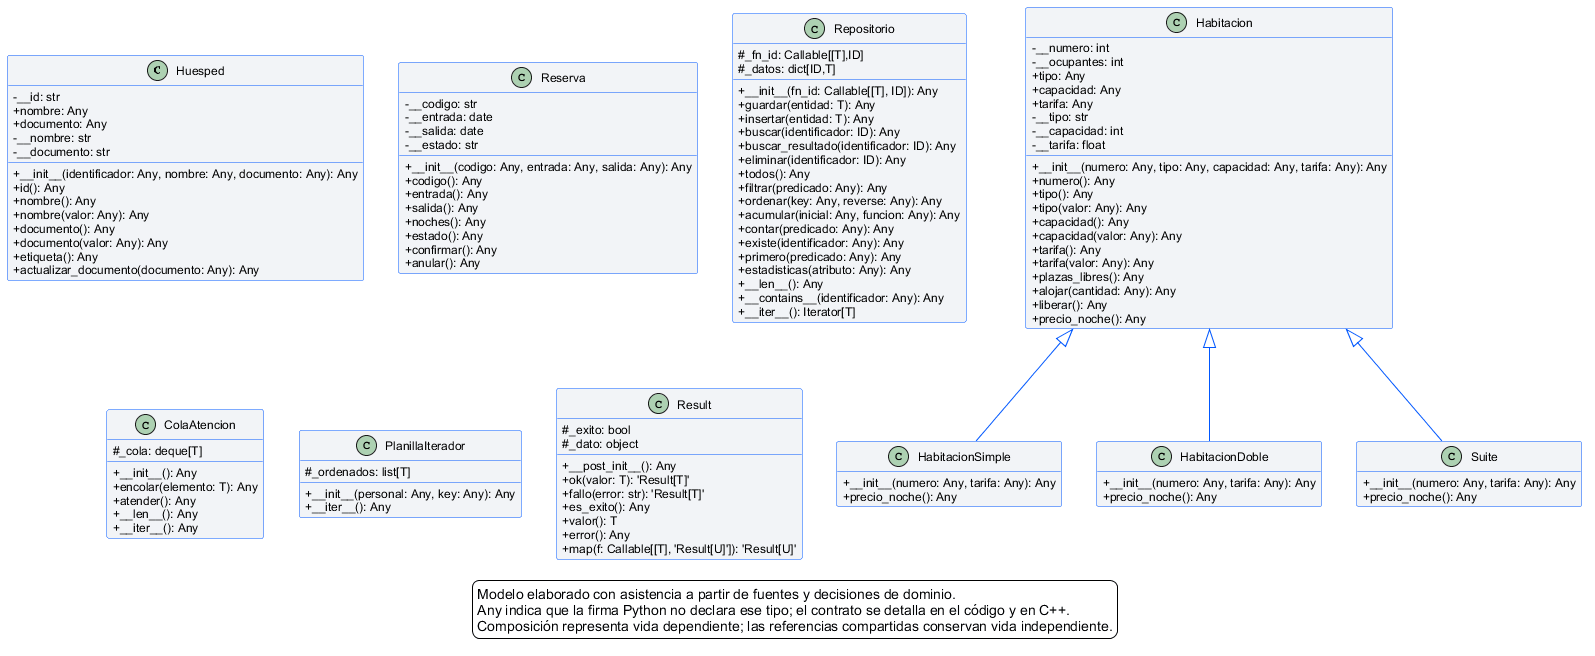

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))


## resumen informe

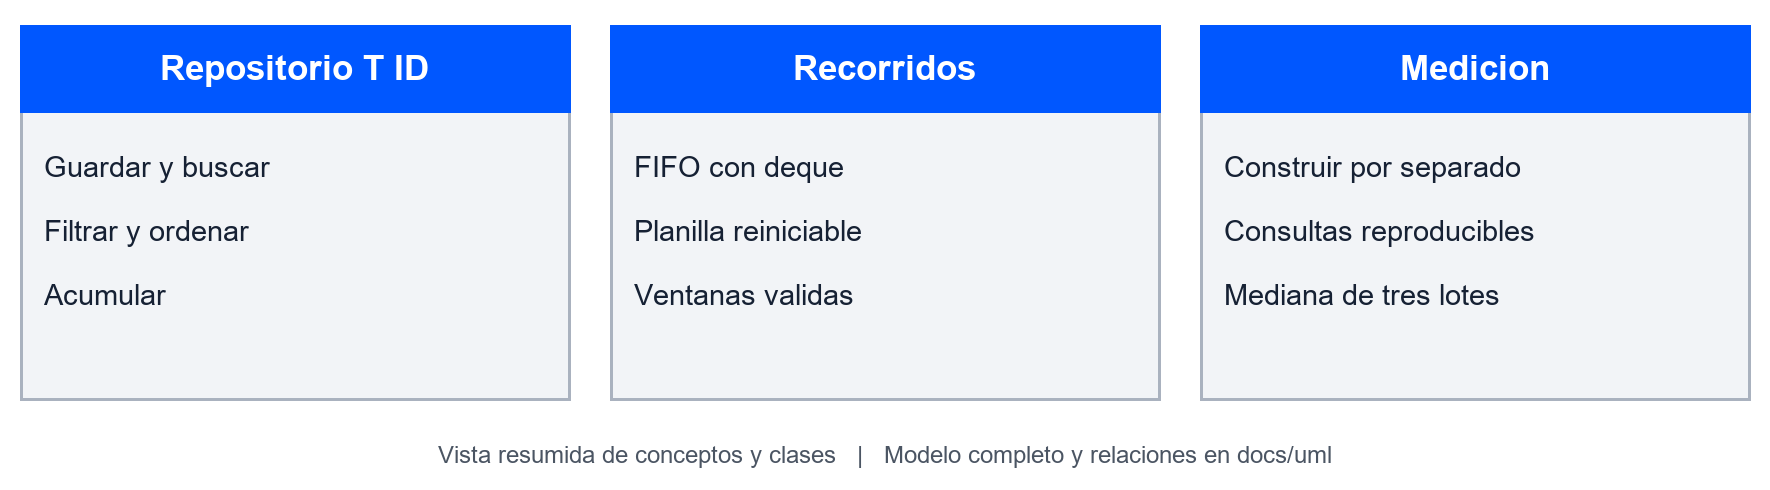

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))
